In [1]:
import sys
src_path = "/home/souvik/codes/FORESEE-main"
sys.path.append(src_path)

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee(path="../../ILCBD/")

energy = "125"
modelname="U1_B-L_see"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast 

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
# masses_brem = [ 
#    0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
#    0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.1413,
#    0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
#    0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
#    0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
#    0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
#    0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
#    1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
#    2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
# ]
files = os.listdir("../../ILCBD/files/125GeV/") 
files_mass = [file.split("_") for file in files]
files_brem = [file for file in files_mass if "Brem" in file]
masses = [file[-1][0:-4] for file in files_brem]
masses_brem = [eval(m) for m in masses]
masses_brem = sorted(masses_brem)

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = "1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
files = os.listdir("../../ILCBD/files/125GeV/") 
files_mass = [file.split("_") for file in files]
files_ep = [file for file in files_mass if "e+" in file]
masses = [file[-1][0:-4] for file in files_ep]
masses_ep = [eval(m) for m in masses]
masses_ep = sorted(masses_ep)

model.add_production_direct(
    label = "e+_Anni",
    energy = energy,
    condition = "1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_ep,
)

In [7]:
masses1 = np.logspace(-3, np.log10(4), 60)
masses2 = np.logspace(np.log10(4),np.log10(6), 40)
masses3 = np.logspace(np.log10(6), 1, 10)
masses = np.array(sorted(list(set(np.concatenate((masses1,masses2,masses3))))))
foresee.set_model(model=model)
# for mass in masses:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=3000, mincount=0, unit="GeV", form=".dat",
#                               path="../../ILCBD/files/",  do_plot=False, stat_cuts=None, save_file=True)

In [8]:
model.set_ctau_1d( folder = "model/",
    filename="ctau_RHN3_e.txt", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    coupling_ref=1
)
branchings = [
    ["visible" , "black"         , "solid" , r"visible"    , 0.110, 0.35],
    ["rhn" ,     "brown"         , "solid" , r"rhn"        , 0.120, 0.45]
]

model.set_br_1d(
    modes=[channel for channel,_,_,_,_,_ in branchings],
    finalstates=[None, None], folder = "model/br_RHN3_e/", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    filenames=[channel+".txt" for channel,_,_,_,_,_ in branchings],
)

In [9]:
rhn_br_old_e={}
for xH in [-2, -1, -0.5, 0, 0.5, 1, 2]:
    rhn_br_old_e[xH] = np.array([model.get_br("rhn", m, xH) for m in masses])

In [10]:
# %%time
# distance, selection, length, luminosity, channels = 81, "np.sqrt(x.x**2 + x.y**2)< 2", 50, 4e22/1000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
# energy, setup, unit, is_integrated = '125', "Ndecay", "GeV", ["111", "221"]
# foresee.set_detector(distance=distance, selection=selection, length=length, is_integrated=is_integrated,
#                      luminosity=luminosity, channels=channels, unit=unit)


# for gX in [1e-5, 1e-6]:
#     #get reach  
#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH = -1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"1n.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = -0.5, model1="U1_X_05n", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     # save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"05n.npy",[masses,couplings,list_nevents])

#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH = 0, model1="B-L_boson", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"0.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = 0.5, model1="U1_X_05p", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"05p.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = 1, model1="U1_X_1p", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"1p.npy",[masses,couplings,list_nevents])


#     #get reach  
#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

In [11]:
# setups = [
#          ["125GeV_Ndecay2n.npy",    "$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay1n.npy",    "$x_H = -1$"  , "blue", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay05n.npy",    "$x_H = -0.5$"  , "green", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay0.npy",     "$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay05p.npy",    "$x_H = 0.5$"  , "red", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay1p.npy",    "$x_H = 1$"  , "maroon", "solid", 0., 3],#*150/3000]]  
#          ["125GeV_Ndecay2p.npy",    "$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
# ]

# for setup in setups:
#     fig, ax = plt.subplots()
#     filename, label, color, ls, alpha, level = setup
#     for gX in [1e-4, 1e-5, 1e-6]:
#         masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/"+str(int(-np.log10(gX)))+"_"+filename, allow_pickle=True, encoding='latin1')
#         m, c = np.meshgrid(masses, couplings**2)
#         n = np.log10(np.array(nsignals).T + 1e-20)
#         ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
#     ax.plot([0],[0],label=label, color=color)
#     ax.set_xscale("log")
#     ax.set_yscale("log")
#     ax.set_xlabel(r"$m_N$ [GeV]") 
#     ax.set_ylabel(r"$U_{1N}^2$")
#     plt.rcParams["figure.figsize"]=(8,6)
#     ax.set_xlim(1e-3, 10)
#     ax.set_ylim(1e-10, 1)
#     ax.legend(loc = "lower left")
#     ax.set_title(r"Z' short-lived, RHN long-lived: $m_N = m_{Z'}/3$")

/tmp/ipykernel_5324/4041409976.py:34: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


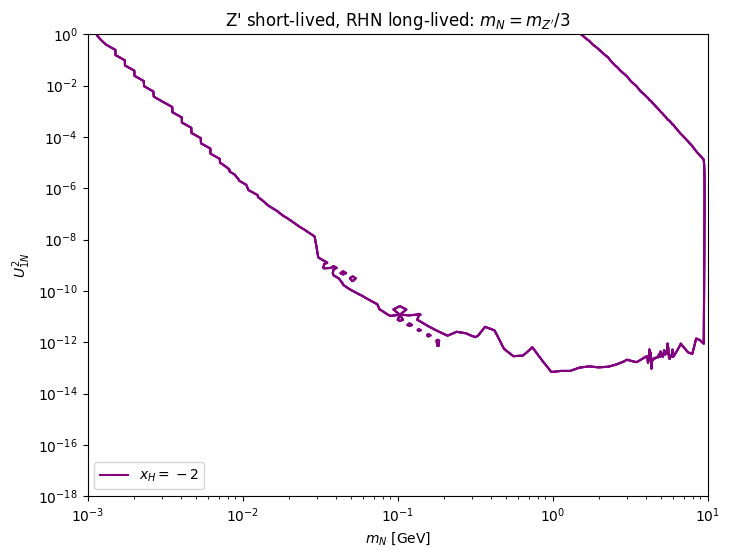

In [19]:
%%time
distance, selection, length, luminosity, channels = 81, "np.sqrt(x.x**2 + x.y**2)< 2", 50, 4e22/1000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, unit, is_integrated = '125', "Ndecay", "GeV", ["111", "221"]
foresee.set_detector(distance=distance, selection=selection, length=length, is_integrated=is_integrated,
                     luminosity=luminosity, channels=channels, unit=unit)

#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    if mass<0.05: size = 1
    elif mass<4.5 and mass>0.05: size = 1
    elif mass>5 and mass<8: size = 5
    else: size = 10
    couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
                                        coup = 0.0025, preselectioncuts="th<2/131", rhn = True,
                                        mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-9,0,90), sample=size)
    list_nevents.append(nevents)  
            
#save results
np.save("model/results_RHN3U_e/0025_"+energy+"GeV_"+setup+"2n.npy",[masses,couplings,list_nevents])

setups = [
         ["125GeV_Ndecay2n.npy",    "$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    for gX in [1e-4, 1e-5, 1e-6]:
        masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_e/0025_"+filename, allow_pickle=True, encoding='latin1')
        m, c = np.meshgrid(masses, couplings**2)
        n = np.log10(np.array(nsignals).T + 1e-20)
        ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_N$ [GeV]") 
    ax.set_ylabel(r"$U_{1N}^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-18, 1)
    ax.legend(loc = "lower left")
    ax.set_title(r"Z' short-lived, RHN long-lived: $m_N = m_{Z'}/3$")

In [13]:
model.set_ctau_1d( folder = "model/",
    filename="ctau_RHN3_mu.txt", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    coupling_ref=1
)
branchings = [
    ["visible" , "black"         , "solid" , r"visible"    , 0.110, 0.35],
    ["rhn" ,     "brown"         , "solid" , r"rhn"        , 0.120, 0.45]
]

model.set_br_1d(
    modes=[channel for channel,_,_,_,_,_ in branchings],
    finalstates=[None, None], folder = "model/br_RHN3_mu/", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    filenames=[channel+".txt" for channel,_,_,_,_,_ in branchings],
)

In [14]:
rhn_br_old_mu={}
for xH in [-2, -1, -0.5, 0, 0.5, 1, 2]:
    rhn_br_old_mu[xH] = np.array([model.get_br("rhn", m, xH) for m in masses])

In [15]:
# %%time
# distance, selection, length, luminosity, channels = 81, "np.sqrt(x.x**2 + x.y**2)< 2", 50, 4e22/1000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
# energy, setup, unit, is_integrated = '125', "Ndecay", "GeV", ["111", "221"]
# foresee.set_detector(distance=distance, selection=selection, length=length, is_integrated=is_integrated,
#                      luminosity=luminosity, channels=channels, unit=unit)


# for gX in [1e-4, 1e-5, 1e-6]:
#     #get reach  
#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH = -1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"1n.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = -0.5, model1="U1_X_05n", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     # save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"05n.npy",[masses,couplings,list_nevents])

#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH = 0, model1="B-L_boson", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"0.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = 0.5, model1="U1_X_05p", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"05p.npy",[masses,couplings,list_nevents])


#     list_nevents = []    
#     # masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass,xH = 1, model1="U1_X_1p", model0="B-L_boson", energy=energy, 
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"1p.npy",[masses,couplings,list_nevents])


#     #get reach  
#     list_nevents = []    
#     #masses = np.logspace(-2, 1, 50)
#     for mass in masses:
#         if mass<0.05: size = 1
#         elif mass<4.5 and mass>0.05: size = 1
#         elif mass>4.5 and mass<8: size = 5
#         else: size = 10
#         couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                         coup = 1e-5, preselectioncuts="th<2/131", rhn = True,
#                                         mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-6,0,60), sample=size)
#         list_nevents.append(nevents)  
            
#     #save results
#     np.save("model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+energy+"GeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

In [16]:
# setups = [
#          ["125GeV_Ndecay2n.npy",    "$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay1n.npy",    "$x_H = -1$"  , "blue", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay05n.npy",    "$x_H = -0.5$"  , "green", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay0.npy",     "$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay05p.npy",    "$x_H = 0.5$"  , "red", "solid", 0., 3],#*150/3000],
#          ["125GeV_Ndecay1p.npy",    "$x_H = 1$"  , "maroon", "solid", 0., 3],#*150/3000]]  
#          ["125GeV_Ndecay2p.npy",    "$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
# ]

# for setup in setups:
#     fig, ax = plt.subplots()
#     filename, label, color, ls, alpha, level = setup
#     for gX in [1e-5, 1e-6]:
#         masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/"+str(int(-np.log10(gX)))+"_"+filename, allow_pickle=True, encoding='latin1')
#         m, c = np.meshgrid(masses, couplings**2)
#         n = np.log10(np.array(nsignals).T + 1e-20)
#         ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
#     ax.plot([0],[0],label=label, color=color)
#     ax.set_xscale("log")
#     ax.set_yscale("log")
#     ax.set_xlabel(r"$m_N$ [GeV]") 
#     ax.set_ylabel(r"$U_{1N}^2$")
#     plt.rcParams["figure.figsize"]=(8,6)
#     ax.set_xlim(1e-3, 10)
#     ax.set_ylim(1e-10, 1)
#     ax.legend(loc = "lower left")
#     ax.set_title(r"Z' short-lived, RHN long-lived: $m_N = m_{Z'}/3$")

/tmp/ipykernel_5324/1251090111.py:33: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


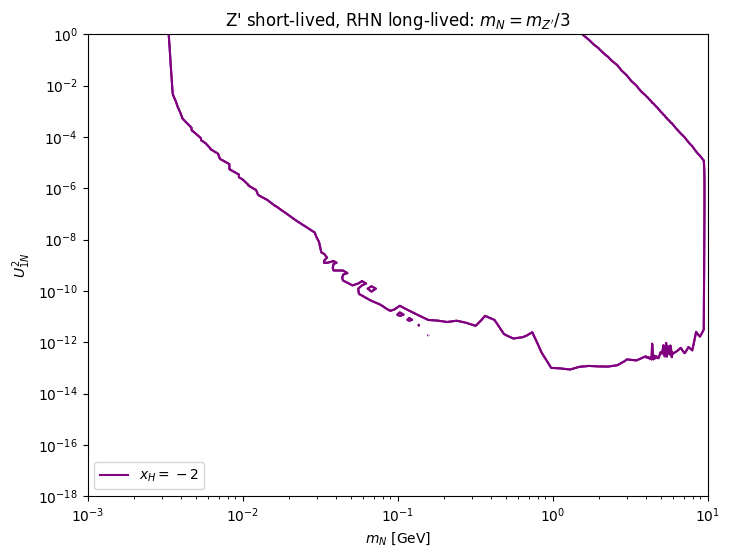

In [18]:
%%time
distance, selection, length, luminosity, channels = 81, "np.sqrt(x.x**2 + x.y**2)< 2", 50, 4e22/1000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, unit, is_integrated = '125', "Ndecay", "GeV", ["111", "221"]
foresee.set_detector(distance=distance, selection=selection, length=length, is_integrated=is_integrated,
                     luminosity=luminosity, channels=channels, unit=unit)
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    if mass<0.05: size = 1
    elif mass<4.5 and mass>0.05: size = 1
    elif mass>5 and mass<8: size = 5
    else: size = 10
    couplings, _, nevents, _, _  = foresee.get_events_mix(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
                                        coup = 0.0025, preselectioncuts="th<2/131", rhn = True,
                                        mN1=1/3, mN2=1/3, mN3=1/3, mixings = np.logspace(-9,0,90), sample=size)
    list_nevents.append(nevents)  
            
#save results
np.save("model/results_RHN3U_mu/0025_"+energy+"GeV_"+setup+"2n.npy",[masses,couplings,list_nevents])

setups = [
         ["125GeV_Ndecay2n.npy",    "$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    for gX in [1e-5, 1e-6]:
        masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3U_mu/0025_"+filename, allow_pickle=True, encoding='latin1')
        m, c = np.meshgrid(masses, couplings**2)
        n = np.log10(np.array(nsignals).T + 1e-20)
        ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_N$ [GeV]") 
    ax.set_ylabel(r"$U_{1N}^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-18, 1)
    ax.legend(loc = "lower left")
    ax.set_title(r"Z' short-lived, RHN long-lived: $m_N = m_{Z'}/3$")

In [10]:
model.set_ctau_1d( folder = "model/",
    filename="ctau_RHN3_phi4.txt", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    coupling_ref=1
)
branchings = [
    ["visible" , "black"         , "solid" , r"visible"    , 0.110, 0.35],
    ["rhn" ,     "brown"         , "solid" , r"rhn"        , 0.120, 0.45]
]

model.set_br_1d(
    modes=[channel for channel,_,_,_,_,_ in branchings],
    finalstates=[None, None], folder = "model/br_RHN3_phi4/", xHs = [-2, -1, -0.5, 0, 0.5, 1, 2],
    filenames=[channel+".txt" for channel,_,_,_,_,_ in branchings],
)

In [11]:
%%time
distance, selection, length, luminosity, channels = 81, "np.sqrt(x.x**2 + x.y**2)< 2", 50, 4e22/1000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, unit, is_integrated = '125', "Ndecay", "GeV", ["111", "221"]
foresee.set_detector(distance=distance, selection=selection, length=length, is_integrated=is_integrated,
                     luminosity=luminosity, channels=channels, unit=unit)

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass, xH = -1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"1n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# # masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass,xH = -0.5, model1="U1_X_phi4_05n", model0="B-L_boson", energy=energy, 
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# # save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"05n.npy",[masses,couplings,list_nevents])

# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass, xH = 0, model1="phi4_B-L_boson", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"0.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# # masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass,xH = 0.5, model1="U1_X_phi4_05p", model0="B-L_boson", energy=energy, 
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"05p.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# # masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass,xH = 1, model1="U1_X_phi4_1p", model0="B-L_boson", energy=energy, 
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"1p.npy",[masses,couplings,list_nevents])


# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     if mass<0.05: size = 1
#     elif mass<4.5 and mass>0.05: size = 1
#     elif mass>4.5 and mass<8: size = 5
#     else: size = 10
#     couplings, _, nevents, _, _  = foresee.get_events_slp(nsample=1, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-6,0,30), preselectioncuts="th<2/131", rhn = True,
#                                     mN1=1/3, mN2=1/3, mN3=1/3, U=1e-5, sample=size)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_phi4/"+energy+"GeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

CPU times: user 25 µs, sys: 8 µs, total: 33 µs
Wall time: 35.3 µs


/tmp/ipykernel_13947/639047441.py:24: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


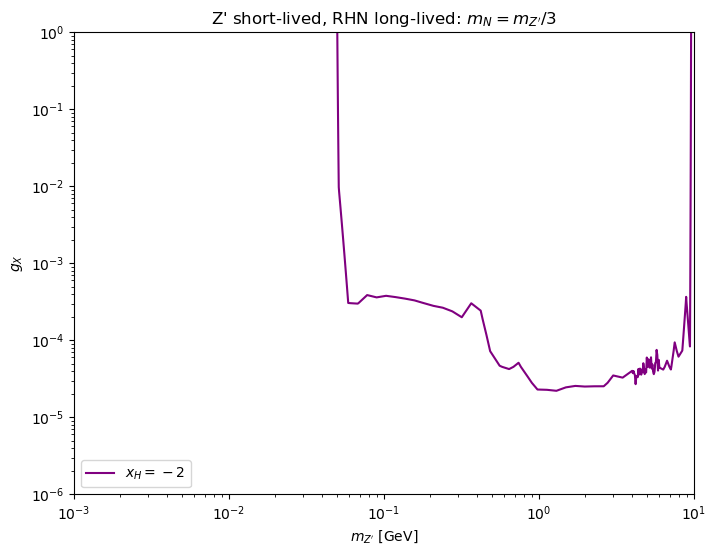

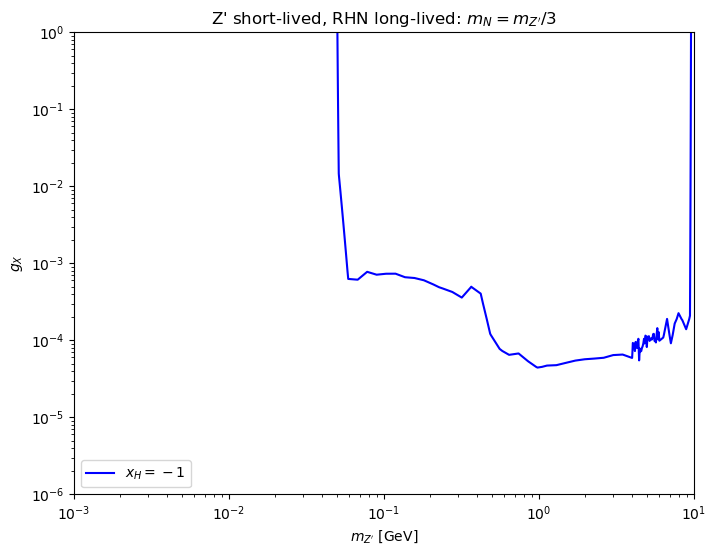

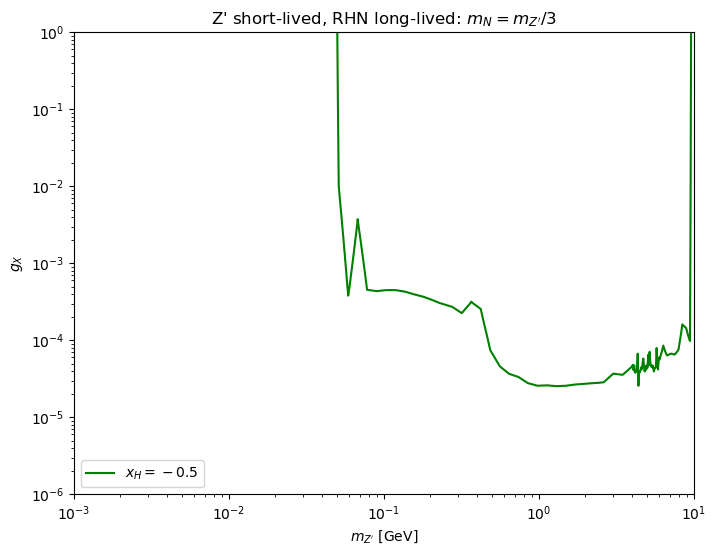

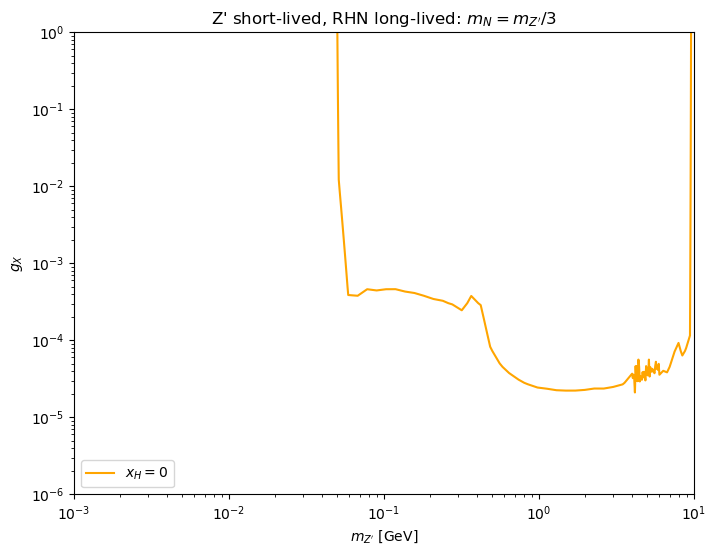

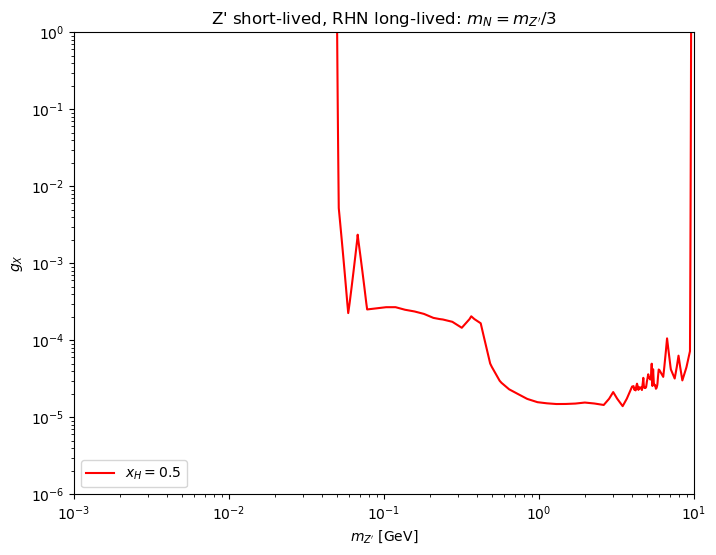

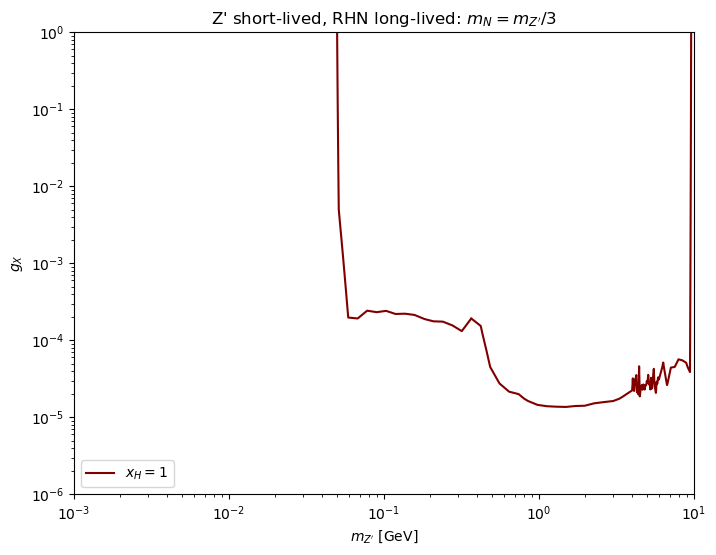

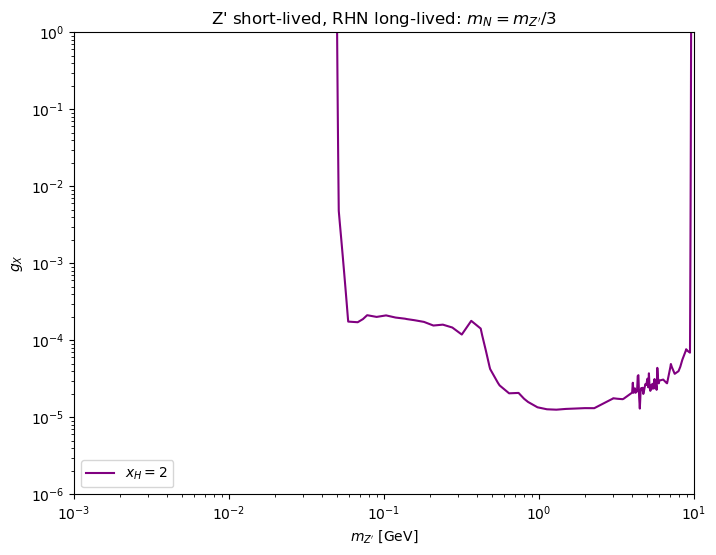

In [13]:
setups = [
         ["125GeV_Ndecay2n.npy",    "$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["125GeV_Ndecay1n.npy",    "$x_H = -1$"  , "blue", "solid", 0., 3],#*150/3000],
         ["125GeV_Ndecay05n.npy",    "$x_H = -0.5$"  , "green", "solid", 0., 3],#*150/3000],
         ["125GeV_Ndecay0.npy",     "$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],
         ["125GeV_Ndecay05p.npy",    "$x_H = 0.5$"  , "red", "solid", 0., 3],#*150/3000],
         ["125GeV_Ndecay1p.npy",    "$x_H = 1$"  , "maroon", "solid", 0., 3],#*150/3000]]  
         ["125GeV_Ndecay2p.npy",    "$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    nsignals = np.array(nsignals)
    xH = label.split("=")[-1].split("$")[0]
    xH = eval(xH)
    for ic in range(len(nsignals)):
        nsignals[ic] = nsignals[ic] * model.get_br("rhn", masses[ic], xH) / rhn_br_old[xH][ic]
    list_nevents = [list(nsignal) for nsignal in nsignals]
    np.save("model/results_RHN3_phi4/"+filename,[masses, couplings, list_nevents])
    n = np.log10(nsignals.T + 1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-6, 1)
    ax.legend(loc = "lower left")
    # plt.axvline(x=5.5)
    ax.set_title(r"Z' short-lived, RHN long-lived: $m_N = m_{Z'}/3$")